# Challenge 3: evaluación final e inferencia

El modelo ya fue seleccionado. Ahora debes abrir el conjunto de test una sola vez, comunicar su desempeño y comprobar que el pipeline puede reutilizarse con datos nuevos.

**Entradas:** `test.csv`, `data_contract.json` y `champion_model.joblib`  
**Salidas:** `test_metrics.json`, `batch_predictions.csv`

In [1]:
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    f1_score,
)

In [2]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

RAW_DATA_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_DIR / "data" / "processed"
ARTIFACTS_DIR = PROJECT_DIR / "artifacts"
REPORTS_DIR = PROJECT_DIR / "reports"

for directory in (PROCESSED_DATA_DIR, ARTIFACTS_DIR, REPORTS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

## 1. Carga del modelo y del conjunto de prueba

In [4]:
contract = json.loads((ARTIFACTS_DIR / "data_contract.json").read_text(encoding="utf-8"))
training_metadata = json.loads((ARTIFACTS_DIR / "training_metadata.json").read_text(encoding="utf-8"))
model = joblib.load(ARTIFACTS_DIR / "champion_model.joblib")

test_df = pd.read_csv(PROCESSED_DATA_DIR / "test.csv")
X_test = test_df[contract["features"]]
y_test = test_df[contract["target"]]

print("Modelo:", training_metadata["champion"])
print("Test:", X_test.shape)

Modelo: Logistic Regression
Test: (36, 12)


## 2. Evaluación final

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        12
           1       0.93      1.00      0.97        14
           2       1.00      0.90      0.95        10

    accuracy                           0.97        36
   macro avg       0.98      0.97      0.97        36
weighted avg       0.97      0.97      0.97        36

Confusion Matrix:


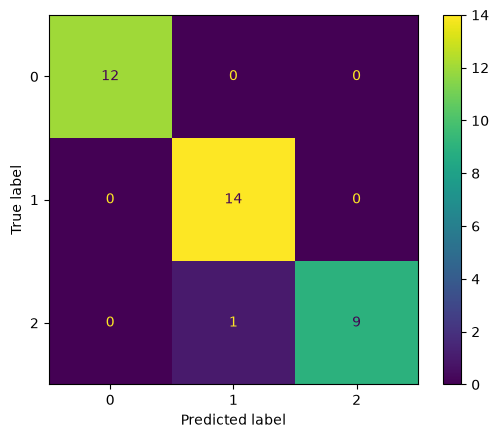

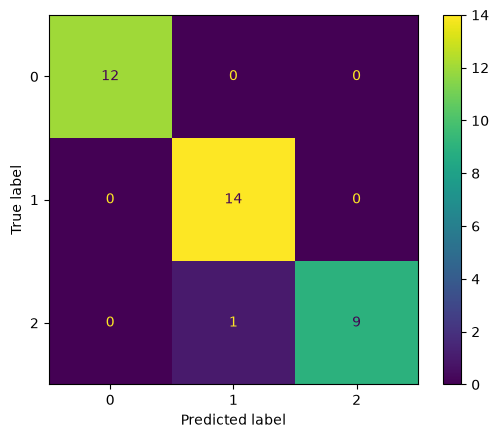

In [5]:
# TODO: calcula predicciones, accuracy y F1 macro
# TODO: muestra classification_report y matriz de confusión
predictions = model.predict(X_test)
accuracy = accuracy_score(y_test, predictions)
f1_macro = f1_score(y_test, predictions, average='macro')

classification_rep = classification_report(y_test, predictions)
confusion_matrix_display = ConfusionMatrixDisplay.from_estimator(model, X_test, y_test)
print("Classification Report:")
print(classification_rep)
print("Confusion Matrix:")
confusion_matrix_display.plot()

**Análisis:**

> ¿El desempeño es coherente con validación cruzada? ¿Qué clases se confunden? ¿Hay evidencia de sobreajuste?

## 3. Función de inferencia

In [9]:
feature_columns = contract["features"]

def predict(records: pd.DataFrame) -> pd.DataFrame:
    """Valida el esquema y devuelve las predicciones del pipeline."""
    # Verifica columnas faltantes
    missing_columns = set(feature_columns) - set(records.columns)
    if missing_columns:
        raise ValueError(f"Faltan columnas: {missing_columns}")
        
    # Ordena y filtra las columnas según el contrato
    records = records[feature_columns]
    
    # Genera predicciones y probabilidades
    predictions = model.predict(records)
    probabilities = model.predict_proba(records)
    
    # Devuelve el DataFrame convirtiendo las probabilidades a lista (evita el error 1D)
    return pd.DataFrame({
        "prediction": predictions,
        "probabilities": probabilities.tolist()  # <-- Cambio clave aquí
    })

## 4. Predicción por lotes

In [17]:
# Simulación de datos nuevos. En producción no provendrían del test set.
new_records = X_test.iloc[:5].copy()

# TODO: llama a predict y guarda batch_predictions.csv

batch_predictions = predict(new_records)
batch_predictions.to_csv(REPORTS_DIR / "batch_predictions.csv", index=False)

## 5. Reporte final

In [18]:
# TODO: guarda test_metrics.json con modelo, accuracy y F1 macro

test_metrics = {
    "model": model.__class__.__name__,
    "accuracy": accuracy,
    "f1_macro": f1_macro
}

with open(REPORTS_DIR / "test_metrics.json", "w") as f:
    json.dump(test_metrics, f)

In [19]:
assert (REPORTS_DIR / "test_metrics.json").exists()
assert (REPORTS_DIR / "batch_predictions.csv").exists()
print("Challenge 3 completado.")

Challenge 3 completado.


## Resumen ejecutivo

| Elemento | Resultado |
|---|---|
| Modelo campeón | |
| Accuracy CV | |
| Accuracy test | |
| F1 macro test | |
| Clases más confundidas | |
| Principal limitación | |

## Checklist

- [ ] Evalué únicamente el modelo campeón.
- [ ] No reajusté hiperparámetros después de observar test.
- [ ] Implementé validación básica del esquema de entrada.
- [ ] Generé predicciones por lotes.
- [ ] Guardé las métricas finales.